# Idea 1: does FTA keep learning stable?
**Fuzzy Tiling Activation** (Pan, Banman & White, ICLR 2021) turns each unit of a layer into 20 sparse values. Sparse features interfere less with each other when the network updates, which the FTA paper found makes RL training more stable, with less variation between runs.

**The only change from the baseline:** the activation of the critic's last hidden layer becomes FTA (20 tiles over [−20, 20], δ = η = 2, as in the FTA paper). Same data, folds, training steps and seeds.

**What "stable" means here:** an agent is stable if retraining it with another random seed gives nearly the same result. So for every test quarter we measure how much the **5 seeds disagree** (standard deviation of that quarter's return). We use the crash rule `none`, so only the agents' own decisions count.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from backtest import STRATEGIES, pretty, sharpe, summary

bt = pd.read_parquet('results/backtest.parquet')
bt = bt[(bt.seed < 5) & bt.variant.isin(['baseline', 'fta'])]   # main runs (extra seeds and 'rolling': 6_investigation)
baselines = pd.read_parquet('results/baselines.parquet')
from scipy.stats import wilcoxon

none = bt[bt.rule == 'none']
quarterly = none.groupby(['variant', 'strategy', 'seed', 'fold']).ret.apply(lambda r: (1 + r).prod() - 1)
spread = quarterly.groupby(['variant', 'strategy', 'fold']).std().unstack('variant')   # disagreement between seeds

## 1. Do the seeds agree more with FTA?
Average seed spread per quarter. "FTA more stable" = share of the 101 quarters where FTA's seeds disagree less. The p-value is a paired Wilcoxon test over the quarters (small = the difference is unlikely to be luck).

In [2]:
rows = {}
for s, g in spread.groupby('strategy'):
    rows[s] = {'Seed spread, baseline': g.baseline.mean(), 'Seed spread, FTA': g.fta.mean(),
               'Quarters where FTA is more stable': (g.fta < g.baseline).mean(),
               'p-value': wilcoxon(g.fta, g.baseline).pvalue}
stability = pd.DataFrame(rows).T.loc[STRATEGIES]
stability.style.format('{:.2%}', subset=stability.columns[:3]).format('{:.3f}', subset=['p-value'])

,"Seed spread, baseline","Seed spread, FTA",Quarters where FTA is more stable,p-value
ensemble,3.00%,2.96%,55.45%,0.234
a2c,3.45%,3.27%,53.47%,0.374
ppo,2.63%,2.67%,46.53%,0.726
ddpg,4.37%,3.94%,54.46%,0.063


## 2. Same question on the validation quarters
How much the validation Sharpe ratio (the number the ensemble uses to pick an agent) varies between seeds.

In [3]:
val = pd.read_csv('results/validation.csv')
val_spread = val.groupby(['variant', 'agent', 'fold']).val_sharpe.std().unstack('variant')
rows = {}
for a, g in val_spread.groupby('agent'):
    rows[a] = {'Val. Sharpe spread, baseline': g.baseline.mean(), 'Val. Sharpe spread, FTA': g.fta.mean(),
               'Folds where FTA is more stable': (g.fta < g.baseline).mean(), 'p-value': wilcoxon(g.fta, g.baseline).pvalue}
pd.DataFrame(rows).T.round(3)

,"Val. Sharpe spread, baseline","Val. Sharpe spread, FTA",Folds where FTA is more stable,p-value
a2c,0.694,0.673,0.554,0.486
ddpg,0.642,0.663,0.485,0.548
ppo,0.606,0.593,0.564,0.266


## 3. Does stability cost performance?
Full period, average over seeds. "Sharpe std over seeds" is another stability measure: how much the final Sharpe ratio changes from seed to seed.

In [4]:
cols = ['Annual return', 'Sharpe (rf = 0)', 'Sharpe std over seeds', 'Max drawdown']
perf = pd.concat({v: summary(none[none.variant == v], baselines)[cols].loc[STRATEGIES] for v in ['baseline', 'fta']}, axis=1)
perf.style.format('{:.1%}').format('{:.2f}', subset=[c for c in perf if 'Sharpe' in c[1]])

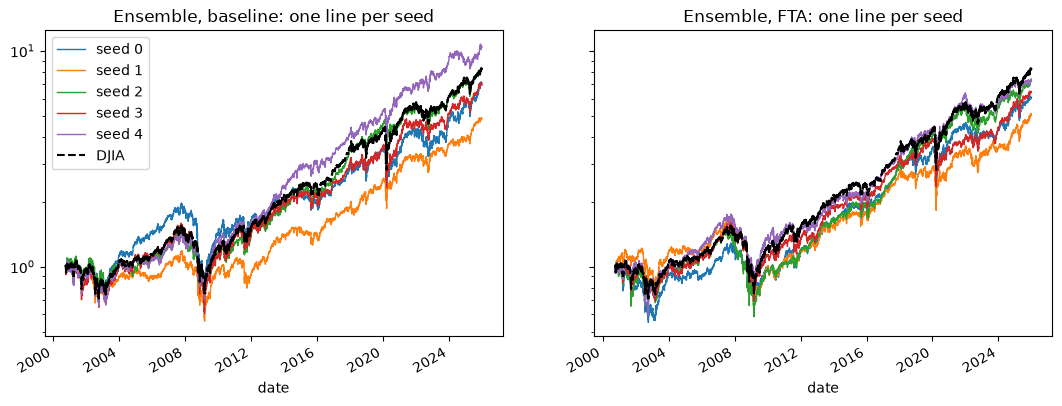

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, v in zip(axes, ['baseline', 'fta']):
    for seed, g in none[(none.variant == v) & (none.strategy == 'ensemble')].groupby('seed'):
        (1 + g.set_index('date').ret).cumprod().plot(ax=ax, lw=1, label=f'seed {seed}')
    (1 + baselines.DJIA).cumprod().plot(ax=ax, color='black', ls='--', label='DJIA')
    ax.set_yscale('log')
    ax.set_title(f'Ensemble, {"FTA" if v == "fta" else "baseline"}: one line per seed')
axes[0].legend();

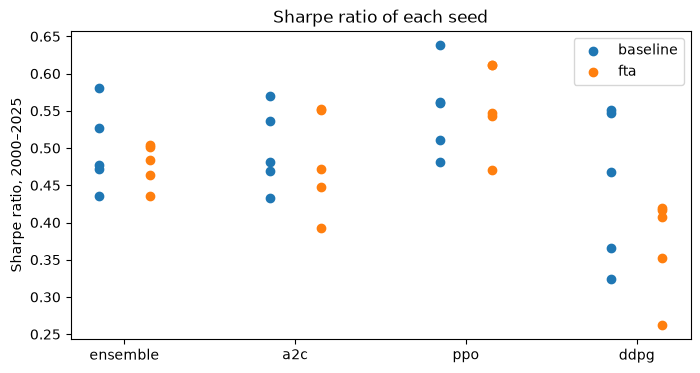

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sh = none.groupby(['variant', 'strategy', 'seed']).ret.apply(sharpe).reset_index()
for i, s in enumerate(STRATEGIES):
    for j, v in enumerate(['baseline', 'fta']):
        y = sh[(sh.strategy == s) & (sh.variant == v)].ret
        ax.scatter([i + (j - 0.5) * 0.3] * len(y), y, color=['tab:blue', 'tab:orange'][j], label=v if i == 0 else None)
ax.set_xticks(range(len(STRATEGIES)), STRATEGIES)
ax.set_ylabel('Sharpe ratio, 2000–2025')
ax.set_title('Sharpe ratio of each seed')
ax.legend();

## Conclusion
**No: in this setting FTA doesn't make the agents measurably more stable, and it doesn't make them better.**
- **Seeds disagree about as much with FTA as without.** The spread of quarterly returns changes by −5% (A2C), −10% (DDPG), −1% (ensemble) and +2% (PPO). FTA is more stable in only 47–55% of quarters, and no difference is significant (smallest p-value: 0.06, for DDPG).
- **Validation Sharpe ratios vary just as much between seeds** (no difference is significant, all p > 0.25). So the ensemble's agent choice isn't more reliable either.
- **Final Sharpe across seeds:** with FTA it varies less for the ensemble (std 0.03 against 0.06) and for DDPG (0.07 against 0.10), but more for A2C (0.07 against 0.06). With 5 seeds these are rough estimates.
- **Performance:** ensemble Sharpe 0.48 against 0.50; PPO unchanged (0.56); DDPG falls from 0.45 to 0.37.
- **The one hint in FTA's favour is DDPG**, the agent closest to the FTA paper's setup (an off-policy critic), where both stability measures improve a little. It comes with lower returns.

**Why so little effect?** FTA is meant to reduce interference when one network keeps learning from changing data. Here every agent is retrained from scratch each quarter for a short time (10k–50k steps), so there's little interference to remove. Most of the seed-to-seed variation probably comes from the noisy reward (daily returns), which FTA doesn't change.